In [24]:
import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim
from sklearn.model_selection import train_test_split

In [25]:
# Paths
DATA_ROOT = "/Users/Rishab/Research"
TARGET_FOLDER = "IR_drop"

SINGLE_CHANNEL_FOLDERS = [
    "power_all",
    "power_i",
    "power_s",
    "power_sca"
]

MULTI_CHANNEL_FOLDER = "power_t"  # 20 time slices

TARGET_SIZE = (320, 320)
BATCH_SIZE = 16

In [26]:
def compute_channel_min_max(file_list):
    channel_min = None
    channel_max = None

    for rel_path in file_list:
        # rel_path = chip/IR_drop/file.npz

        chip = rel_path.split(os.sep)[0]
        filename = rel_path.split(os.sep)[-1]

        power_maps = []

        # Single-channel inputs
        for folder in SINGLE_CHANNEL_FOLDERS:
            path = os.path.join(DATA_ROOT, chip, folder, filename)

            arr = np.load(path)
            if isinstance(arr, np.lib.npyio.NpzFile):
                arr = list(arr.values())[0]
            arr = arr.astype(np.float32)

            if arr.ndim == 2:
                arr = arr[..., np.newaxis]

            power_maps.append(arr)

        # Multi-channel power_t
        path = os.path.join(DATA_ROOT, chip, MULTI_CHANNEL_FOLDER, filename)

        arr = np.load(path)
        if isinstance(arr, np.lib.npyio.NpzFile):
            arr = list(arr.values())[0]
        arr = arr.astype(np.float32)

        if arr.ndim == 3 and arr.shape[0] == 20:
            arr = np.transpose(arr, (1, 2, 0))

        power_maps.append(arr)

        X = np.concatenate(power_maps, axis=-1)

        sample_min = X.min(axis=(0, 1))
        sample_max = X.max(axis=(0, 1))

        if channel_min is None:
            channel_min = sample_min
            channel_max = sample_max
        else:
            channel_min = np.minimum(channel_min, sample_min)
            channel_max = np.maximum(channel_max, sample_max)

    return channel_min, channel_max

In [27]:
# ----------------------------
# File split
# ----------------------------
CHIPS = [
    "Vortex-small",
    #"Vortex-large",
    #"nvdla-large",
    "nvdla-small",
    "openc910-1",
    "RISCY",
    "RISCY-FPU",
    "zero-riscy"
]

TARGET_FOLDER = "IR_drop"

all_files = []
chip_names = []

for chip in CHIPS:
    ir_dir = os.path.join(DATA_ROOT, chip, TARGET_FOLDER)

    for f in sorted(os.listdir(ir_dir)):
        valid = True

        # check all required inputs exist
        for folder in SINGLE_CHANNEL_FOLDERS + [MULTI_CHANNEL_FOLDER]:
            path = os.path.join(DATA_ROOT, chip, folder, f)
            if not os.path.exists(path):
                valid = False
                break

        if valid:
            all_files.append(os.path.join(chip, TARGET_FOLDER, f))
            chip_names.append(chip)

# 80% train, 20% temp
train_files, temp_files, train_labels, temp_labels = train_test_split(
    all_files,
    chip_names,
    test_size=0.2,
    random_state=42,
    stratify=chip_names
)

# split temp → 10% val, 10% test
val_files, test_files, val_labels, test_labels = train_test_split(
    temp_files,
    temp_labels,
    test_size=0.5,
    random_state=42,
    stratify=temp_labels
)

# Compute channel-wise min/max on training set
CHANNEL_MIN, CHANNEL_MAX = compute_channel_min_max(train_files)
CHANNEL_MIN_TF = tf.constant(CHANNEL_MIN, dtype=tf.float32)
CHANNEL_MAX_TF = tf.constant(CHANNEL_MAX, dtype=tf.float32)

print("CHANNEL_MIN:", CHANNEL_MIN)
print("CHANNEL_MAX:", CHANNEL_MAX)

CHANNEL_MIN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
CHANNEL_MAX: [8.4712585e+02 6.7081171e+02 2.4045189e+02 1.1964625e+06 1.3663698e+02
 1.1267889e+03 4.4318524e+02 1.1426882e+06 1.1964489e+06 1.0698599e+06
 4.8098009e+05 6.6905956e+05 6.6874119e+05 6.6858400e+05 6.6760650e+05
 6.6747975e+05 4.9396544e+05 4.0844016e+05 7.0807123e+02 7.0782605e+02
 7.0773151e+02 9.0294676e+00 7.2237887e+00 6.3507800e+00]


In [28]:
for chip in CHIPS:
    path = os.path.join(DATA_ROOT, chip, TARGET_FOLDER)
    print(chip, len(os.listdir(path)))

Vortex-small 96
nvdla-small 85
openc910-1 96
RISCY 3170
RISCY-FPU 3456
zero-riscy 3456


In [29]:
for chip in CHIPS:
    vals = []

    chip_files = [f for f in all_files if f.startswith(chip)]

    for rel in chip_files:
        arr = np.load(os.path.join(DATA_ROOT, rel))
        if isinstance(arr, np.lib.npyio.NpzFile):
            arr = list(arr.values())[0]
        vals.append(arr.max())

    print(chip, np.max(vals), np.mean(vals))

Vortex-small 1386.04 349.9682604166666
nvdla-small 1038.36 369.0019058823529
openc910-1 2628.57 387.2102958333333
RISCY 1230.39 130.6121109700816
RISCY-FPU 1230.39 138.82606987847223
zero-riscy 605.268 118.03035561342594


In [30]:
# ----------------------------
# STEP 2: Dataset loader with channel-wise normalization
# ----------------------------
def load_npy(path):
    def _load(path):
        arr_file = np.load(path.decode("utf-8"))
        if isinstance(arr_file, np.lib.npyio.NpzFile):
            arr = list(arr_file.values())[0]
        else:
            arr = arr_file
        arr = arr.astype(np.float32)
        if arr.ndim == 2:
            arr = arr[..., np.newaxis]
        return arr

    tensor = tf.numpy_function(_load, [path], tf.float32)
    tensor.set_shape([None, None, None])
    tensor = tf.image.resize(tensor, TARGET_SIZE)
    return tensor

In [31]:
def load_sample(rel_path):
    # rel_path = "chip_name/IR_drop/file.npz"

    y_path = tf.strings.join([DATA_ROOT, rel_path], separator=os.sep)
    y = load_npy(y_path)
    #y = tf.clip_by_value(y, 0.0, 30.0)

    chip = tf.strings.split(rel_path, os.sep)[0]
    filename = tf.strings.split(rel_path, os.sep)[-1]

    power_maps = []

    # single-channel inputs
    for folder in SINGLE_CHANNEL_FOLDERS:
        x_path = tf.strings.join(
            [DATA_ROOT, chip, folder, filename],
            separator=os.sep
        )
        x = load_npy(x_path)
        power_maps.append(x)

    # multi-channel
    power_t_path = tf.strings.join(
        [DATA_ROOT, chip, MULTI_CHANNEL_FOLDER, filename],
        separator=os.sep
    )

    def load_power_t(path):
        arr_file = np.load(path.decode("utf-8"))
        if isinstance(arr_file, np.lib.npyio.NpzFile):
            arr = list(arr_file.values())[0]
        else:
            arr = arr_file
        arr = arr.astype(np.float32)
        if arr.ndim == 3 and arr.shape[0] == 20:
            arr = np.transpose(arr, (1, 2, 0))
        return arr

    power_t = tf.numpy_function(load_power_t, [power_t_path], tf.float32)
    power_t.set_shape([None, None, 20])
    power_t = tf.image.resize(power_t, TARGET_SIZE)

    power_maps.append(power_t)

    X = tf.concat(power_maps, axis=-1)

    # normalize
    X = (X - CHANNEL_MIN_TF) / (CHANNEL_MAX_TF - CHANNEL_MIN_TF + 1e-8)

    return X, y

In [32]:
# ----------------------------
# STEP 3: Build datasets
# ----------------------------
train_dataset = (
    tf.data.Dataset.from_tensor_slices(train_files)
    .map(load_sample, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(len(train_files))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_dataset = (
    tf.data.Dataset.from_tensor_slices(val_files)
    .map(load_sample, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_dataset = (
    tf.data.Dataset.from_tensor_slices(test_files)
    .map(load_sample, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

In [33]:
def compute_global_max(dataset):
    global_max = 0.0

    for _, y_batch in dataset:
        batch_max = tf.reduce_max(y_batch)
        global_max = max(global_max, float(batch_max))

    return global_max

train_max = compute_global_max(train_dataset)
val_max   = compute_global_max(val_dataset)
test_max  = compute_global_max(test_dataset)

print("Train max:", train_max)
print("Val max:", val_max)
print("Test max:", test_max)

I0000 00:00:1784510954.284602 5558606 shuffle_dataset_op.cc:453] ShuffleDatasetV3:1836: Filling up shuffle buffer (this may take a while): 2142 of 8280
I0000 00:00:1784510974.253370 5558606 shuffle_dataset_op.cc:453] ShuffleDatasetV3:1836: Filling up shuffle buffer (this may take a while): 6348 of 8280
I0000 00:00:1784510983.901408 5558606 shuffle_dataset_op.cc:483] Shuffle buffer filled.


Train max: 2417.285888671875
Val max: 864.9192504882812
Test max: 2418.465087890625


In [34]:
print("Train:", len(train_files))
print("Val:", len(val_files))
print("Test:", len(test_files))

for X, y in train_dataset.take(1):
    print("X:", X.shape)  # (B, 300, 300, 24)
    print("y:", y.shape)  # (B, 300, 300, 1)

Train: 8280
Val: 1035
Test: 1036


I0000 00:00:1784511011.001351 5560117 shuffle_dataset_op.cc:453] ShuffleDatasetV3:1836: Filling up shuffle buffer (this may take a while): 2284 of 8280
I0000 00:00:1784511021.006864 5560117 shuffle_dataset_op.cc:453] ShuffleDatasetV3:1836: Filling up shuffle buffer (this may take a while): 4444 of 8280
I0000 00:00:1784511039.459692 5560117 shuffle_dataset_op.cc:483] Shuffle buffer filled.


X: (16, 320, 320, 24)
y: (16, 320, 320, 1)


In [35]:
import time


# =========================================================
# LEARNABLE POSITION EMBEDDING
# =========================================================

@tf.keras.utils.register_keras_serializable()
class AddPositionEmbedding(layers.Layer):
    def __init__(self, num_patches, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.num_patches = num_patches
        self.embed_dim = embed_dim

        self.position_embedding = layers.Embedding(
            input_dim=num_patches,
            output_dim=embed_dim,
            name="embedding"
        )

    def call(self, inputs):
        positions = tf.range(
            start=0,
            limit=self.num_patches,
            delta=1
        )

        position_vectors = self.position_embedding(positions)

        return inputs + position_vectors[tf.newaxis, :, :]

    def get_config(self):
        config = super().get_config()
        config.update({
            "num_patches": self.num_patches,
            "embed_dim": self.embed_dim
        })
        return config


# =========================================================
# TRANSFORMER MLP
# =========================================================

def transformer_mlp(x, mlp_dim, embed_dim, dropout, name):
    x = layers.Dense(
        mlp_dim,
        activation=tf.keras.activations.gelu,
        name=f"{name}_dense1"
    )(x)

    x = layers.Dropout(
        dropout,
        name=f"{name}_dropout1"
    )(x)

    x = layers.Dense(
        embed_dim,
        name=f"{name}_dense2"
    )(x)

    x = layers.Dropout(
        dropout,
        name=f"{name}_dropout2"
    )(x)

    return x


# =========================================================
# PRE-NORM TRANSFORMER ENCODER BLOCK
# =========================================================

def transformer_block(
    x,
    embed_dim,
    num_heads,
    mlp_dim,
    dropout,
    name
):
    if embed_dim % num_heads != 0:
        raise ValueError(
            "embed_dim must be divisible by num_heads. "
            f"Received embed_dim={embed_dim}, "
            f"num_heads={num_heads}."
        )

    # -----------------------------------------------------
    # Multi-head self-attention
    # -----------------------------------------------------

    normalized_x = layers.LayerNormalization(
        epsilon=1e-6,
        name=f"{name}_attention_norm"
    )(x)

    attention_output = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=dropout,
        name=f"{name}_attention"
    )(
        normalized_x,
        normalized_x
    )

    attention_output = layers.Dropout(
        dropout,
        name=f"{name}_attention_dropout"
    )(attention_output)

    x = layers.Add(name=f"{name}_attention_residual")([
        x,
        attention_output
    ])

    # -----------------------------------------------------
    # Transformer MLP
    # -----------------------------------------------------

    normalized_x = layers.LayerNormalization(
        epsilon=1e-6,
        name=f"{name}_mlp_norm"
    )(x)

    mlp_output = transformer_mlp(
        normalized_x,
        mlp_dim=mlp_dim,
        embed_dim=embed_dim,
        dropout=dropout,
        name=f"{name}_mlp"
    )

    x = layers.Add(name=f"{name}_mlp_residual")([
        x,
        mlp_output
    ])

    return x


# =========================================================
# CONVOLUTIONAL DECODER BLOCK
# =========================================================

def decoder_block(x, filters, name):
    x = layers.UpSampling2D(
        size=2,
        interpolation="bilinear",
        name=f"{name}_upsample"
    )(x)

    x = layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same",
        use_bias=False,
        name=f"{name}_conv1"
    )(x)
    x = layers.BatchNormalization(name=f"{name}_bn1")(x)
    x = layers.Activation("relu", name=f"{name}_relu1")(x)

    x = layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same",
        use_bias=False,
        name=f"{name}_conv2"
    )(x)
    x = layers.BatchNormalization(name=f"{name}_bn2")(x)
    x = layers.Activation("relu", name=f"{name}_relu2")(x)

    return x


# =========================================================
# VISION TRANSFORMER
# =========================================================

def build_vit(
    input_shape=(320, 320, 24),
    patch_size=16,
    embed_dim=192,
    depth=6,
    num_heads=6,
    mlp_dim=384,
    dropout=0.1
):
    height, width, _ = input_shape

    if height % patch_size != 0 or width % patch_size != 0:
        raise ValueError(
            "Input height and width must be divisible by patch_size. "
            f"Received input_shape={input_shape}, "
            f"patch_size={patch_size}."
        )

    if embed_dim % num_heads != 0:
        raise ValueError(
            "embed_dim must be divisible by num_heads. "
            f"Received embed_dim={embed_dim}, "
            f"num_heads={num_heads}."
        )

    grid_height = height // patch_size
    grid_width = width // patch_size
    num_patches = grid_height * grid_width

    inputs = layers.Input(
        shape=input_shape,
        name="input"
    )

    # -----------------------------------------------------
    # Patch extraction and linear projection
    #
    # A Conv2D with kernel_size=stride=patch_size performs
    # non-overlapping patch extraction and projection.
    # -----------------------------------------------------

    x = layers.Conv2D(
        filters=embed_dim,
        kernel_size=patch_size,
        strides=patch_size,
        padding="valid",
        name="patch_embedding"
    )(inputs)

    # For 320×320 inputs and 16×16 patches:
    # (B, 20, 20, embed_dim) -> (B, 400, embed_dim)
    x = layers.Reshape(
        target_shape=(num_patches, embed_dim),
        name="patch_sequence"
    )(x)

    # -----------------------------------------------------
    # Learnable position embeddings
    # -----------------------------------------------------

    x = AddPositionEmbedding(
        num_patches=num_patches,
        embed_dim=embed_dim,
        name="position_embedding"
    )(x)

    x = layers.Dropout(
        dropout,
        name="embedding_dropout"
    )(x)

    # -----------------------------------------------------
    # Transformer encoder
    # -----------------------------------------------------

    for block_index in range(depth):
        x = transformer_block(
            x,
            embed_dim=embed_dim,
            num_heads=num_heads,
            mlp_dim=mlp_dim,
            dropout=dropout,
            name=f"transformer_{block_index + 1}"
        )

    x = layers.LayerNormalization(
        epsilon=1e-6,
        name="encoder_norm"
    )(x)

    # -----------------------------------------------------
    # Convert patch tokens back into a spatial feature map
    # -----------------------------------------------------

    x = layers.Reshape(
        target_shape=(grid_height, grid_width, embed_dim),
        name="tokens_to_grid"
    )(x)

    # -----------------------------------------------------
    # Dense prediction decoder
    #
    # 20 -> 40 -> 80 -> 160 -> 320
    # -----------------------------------------------------

    x = decoder_block(x, 256, name="decoder1")
    x = decoder_block(x, 128, name="decoder2")
    x = decoder_block(x, 64, name="decoder3")
    x = decoder_block(x, 32, name="decoder4")

    outputs = layers.Conv2D(
        filters=1,
        kernel_size=1,
        padding="same",
        activation="linear",
        name="ir_drop"
    )(x)

    return models.Model(
        inputs=inputs,
        outputs=outputs,
        name="vanilla_vit_ir_drop"
    )


model = build_vit()
model.summary()

# Optional smoke test
assert vit_model.input_shape == (None, 320, 320, 24)
assert vit_model.output_shape == (None, 320, 320, 1)

Model: "vanilla_vit_ir_drop"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, 320, 320,  │          0 │ -                 │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_embedding     │ (None, 20, 20,    │  1,179,840 │ input[0][0]       │
│ (Conv2D)            │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_sequence      │ (None, 400, 192)  │          0 │ patch_embedding[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ position_embedding  │ (None, 400, 192)  │     76,800 │ patch_sequence[0… │
│ (AddPositionEmbedd… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_dropout   │ (None, 400, 192)  │          0 │ position_embeddi… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_atte… │ (None, 400, 192)  │        384 │ embedding_dropou… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_atte… │ (None, 400, 192)  │    148,224 │ transformer_1_at… │
│ (MultiHeadAttentio… │                   │            │ transformer_1_at… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_atte… │ (None, 400, 192)  │          0 │ transformer_1_at… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_atte… │ (None, 400, 192)  │          0 │ embedding_dropou… │
│ (Add)               │                   │            │ transformer_1_at… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_mlp_… │ (None, 400, 192)  │        384 │ transformer_1_at… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_mlp_… │ (None, 400, 384)  │     74,112 │ transformer_1_ml… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_mlp_… │ (None, 400, 384)  │          0 │ transformer_1_ml… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_mlp_… │ (None, 400, 192)  │     73,920 │ transformer_1_ml… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_mlp_… │ (None, 400, 192)  │          0 │ transformer_1_ml… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_mlp_… │ (None, 400, 192)  │          0 │ transformer_1_at… │
│ (Add)               │                   │            │ transformer_1_ml… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_2_atte… │ (None, 400, 192)  │        384 │ transformer_1_ml… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_2_atte… │ (None, 400, 192)  │    148,224 │ transformer_2_at

 Total params: 4,655,841 (17.76 MB)

 Trainable params: 4,653,921 (17.75 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [40]:
# =========================================================
# TIMER CALLBACK
# =========================================================

class TimeHistory(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch_start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):
        elapsed = time.time() - self.epoch_start_time
        self.times.append(elapsed)
        print(f"\nEpoch {epoch + 1} took {elapsed:.2f} seconds ({elapsed / 60:.2f} minutes)")


time_callback = TimeHistory()
total_start = time.time()


# =========================================================
# CALLBACKS
# =========================================================

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "best_vit.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)


# =========================================================
# TRAINING
# =========================================================

print("\n========================================")
print("TRAINING VIT FROM SCRATCH")
print("========================================\n")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4),
    loss="mse",
    metrics=["mae"]
)

train_start = time.time()

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    callbacks=[
        early_stop,
        reduce_lr,
        checkpoint,
        time_callback
    ]
)

train_end = time.time()

model.load_weights("best_vit.keras")
model.save("final_vit_ir_model.keras")

total_end = time.time()
total_seconds = total_end - total_start

print("\n========================================")
print("VIT TRAINING COMPLETE")
print("========================================")
print(f"Training time: {(train_end - train_start):.2f} seconds")
print(f"Training time: {(train_end - train_start) / 60:.2f} minutes")
print(f"Average epoch time: {sum(time_callback.times) / len(time_callback.times):.2f} seconds")
print(f"Total runtime: {total_seconds:.2f} seconds")
print(f"Total runtime: {total_seconds / 60:.2f} minutes")
print(f"Total runtime: {total_seconds / 3600:.2f} hours")


TRAINING VIT FROM SCRATCH

Epoch 1/20


I0000 00:00:1784534828.495252 6176715 shuffle_dataset_op.cc:453] ShuffleDatasetV3:1836: Filling up shuffle buffer (this may take a while): 1991 of 8280
I0000 00:00:1784534838.509448 6176715 shuffle_dataset_op.cc:453] ShuffleDatasetV3:1836: Filling up shuffle buffer (this may take a while): 3915 of 8280
I0000 00:00:1784534858.457996 6176715 shuffle_dataset_op.cc:453] ShuffleDatasetV3:1836: Filling up shuffle buffer (this may take a while): 8117 of 8280
I0000 00:00:1784534859.141235 6176715 shuffle_dataset_op.cc:483] Shuffle buffer filled.


518/518 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - loss: 82.3070 - mae: 3.8490
Epoch 1: val_loss improved from None to 79.82256, saving model to best_vit.keras

Epoch 1: finished saving model to best_vit.keras

Epoch 1 took 1081.33 seconds (18.02 minutes)
518/518 ━━━━━━━━━━━━━━━━━━━━ 1081s 2s/step - loss: 80.6850 - mae: 3.8667 - val_loss: 79.8226 - val_mae: 4.3228 - learning_rate: 5.0000e-04
Epoch 2/20


I0000 00:00:1784535904.038012 6197209 shuffle_dataset_op.cc:453] ShuffleDatasetV3:1836: Filling up shuffle buffer (this may take a while): 2222 of 8280
I0000 00:00:1784535914.051516 6197209 shuffle_dataset_op.cc:453] ShuffleDatasetV3:1836: Filling up shuffle buffer (this may take a while): 4400 of 8280
I0000 00:00:1784535924.057898 6197209 shuffle_dataset_op.cc:453] ShuffleDatasetV3:1836: Filling up shuffle buffer (this may take a while): 6533 of 8280
I0000 00:00:1784535932.237589 6197209 shuffle_dataset_op.cc:483] Shuffle buffer filled.


518/518 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - loss: 78.6610 - mae: 3.8237
Epoch 2: val_loss did not improve from 79.82256

Epoch 2 took 1094.42 seconds (18.24 minutes)
518/518 ━━━━━━━━━━━━━━━━━━━━ 1094s 2s/step - loss: 80.1759 - mae: 3.8351 - val_loss: 109.4980 - val_mae: 5.6259 - learning_rate: 5.0000e-04
Epoch 3/20


I0000 00:00:1784536998.456908 6222482 shuffle_dataset_op.cc:453] ShuffleDatasetV3:1836: Filling up shuffle buffer (this may take a while): 2263 of 8280
I0000 00:00:1784537008.480243 6222482 shuffle_dataset_op.cc:453] ShuffleDatasetV3:1836: Filling up shuffle buffer (this may take a while): 4363 of 8280
I0000 00:00:1784537027.378334 6222482 shuffle_dataset_op.cc:483] Shuffle buffer filled.


... (15 outputs left out)

I0000 00:00:1784545529.735223 6331958 shuffle_dataset_op.cc:453] ShuffleDatasetV3:1836: Filling up shuffle buffer (this may take a while): 2292 of 8280
I0000 00:00:1784545549.731413 6331958 shuffle_dataset_op.cc:453] ShuffleDatasetV3:1836: Filling up shuffle buffer (this may take a while): 6749 of 8280
I0000 00:00:1784545556.683891 6331958 shuffle_dataset_op.cc:483] Shuffle buffer filled.


518/518 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - loss: 63.2010 - mae: 3.4403
Epoch 11: ReduceLROnPlateau reducing learning rate to 3.125000148429535e-05.

Epoch 11: val_loss did not improve from 67.56454

Epoch 11 took 1057.65 seconds (17.63 minutes)
518/518 ━━━━━━━━━━━━━━━━━━━━ 1058s 2s/step - loss: 65.8017 - mae: 3.4568 - val_loss: 71.0838 - val_mae: 3.9100 - learning_rate: 6.2500e-05
Epoch 12/20


I0000 00:00:1784546587.392590 6344006 shuffle_dataset_op.cc:453] ShuffleDatasetV3:1836: Filling up shuffle buffer (this may take a while): 2280 of 8280
I0000 00:00:1784546607.427548 6344006 shuffle_dataset_op.cc:453] ShuffleDatasetV3:1836: Filling up shuffle buffer (this may take a while): 6751 of 8280
I0000 00:00:1784546614.236209 6344006 shuffle_dataset_op.cc:483] Shuffle buffer filled.


518/518 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - loss: 67.8941 - mae: 3.4511
Epoch 12: val_loss did not improve from 67.56454

Epoch 12 took 1060.20 seconds (17.67 minutes)
518/518 ━━━━━━━━━━━━━━━━━━━━ 1060s 2s/step - loss: 64.7385 - mae: 3.4355 - val_loss: 68.4769 - val_mae: 3.8150 - learning_rate: 3.1250e-05

VIT TRAINING COMPLETE
Training time: 12825.01 seconds
Training time: 213.75 minutes
Average epoch time: 1068.74 seconds
Total runtime: 12825.85 seconds
Total runtime: 213.76 minutes
Total runtime: 3.56 hours


In [41]:
# Evaluate on train, val, test
train_metrics = model.evaluate(train_dataset)
val_metrics   = model.evaluate(val_dataset)
test_metrics  = model.evaluate(test_dataset)

print("Train metrics (loss, MAE):", train_metrics)
print("Val metrics (loss, MAE):", val_metrics)
print("Test metrics (loss, MAE):", test_metrics)

I0000 00:00:1784547648.458997 6356777 shuffle_dataset_op.cc:453] ShuffleDatasetV3:1836: Filling up shuffle buffer (this may take a while): 2182 of 8280
I0000 00:00:1784547658.462469 6356777 shuffle_dataset_op.cc:453] ShuffleDatasetV3:1836: Filling up shuffle buffer (this may take a while): 4265 of 8280
I0000 00:00:1784547668.488298 6356777 shuffle_dataset_op.cc:453] ShuffleDatasetV3:1836: Filling up shuffle buffer (this may take a while): 6495 of 8280
I0000 00:00:1784547676.495952 6356777 shuffle_dataset_op.cc:483] Shuffle buffer filled.


518/518 ━━━━━━━━━━━━━━━━━━━━ 318s 540ms/step - loss: 64.8791 - mae: 3.3144
65/65 ━━━━━━━━━━━━━━━━━━━━ 37s 556ms/step - loss: 67.5645 - mae: 3.5256
65/65 ━━━━━━━━━━━━━━━━━━━━ 36s 558ms/step - loss: 83.1196 - mae: 3.5760
Train metrics (loss, MAE): [64.8790512084961, 3.3144054412841797]
Val metrics (loss, MAE): [67.56453704833984, 3.5255706310272217]
Test metrics (loss, MAE): [83.11956024169922, 3.5760092735290527]


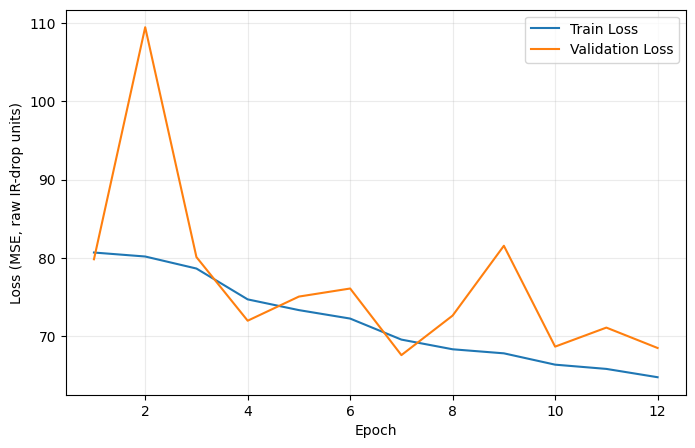

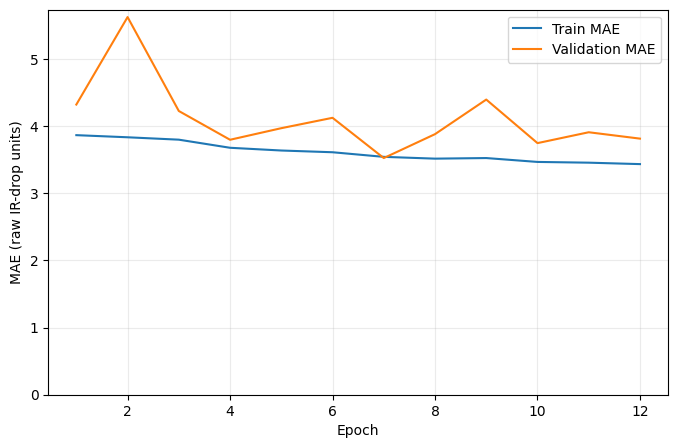

In [42]:
train_loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(train_loss) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss, label="Train Loss")
plt.plot(epochs, val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE, raw IR-drop units)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

train_mae = history.history["mae"]
val_mae = history.history["val_mae"]

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_mae, label="Train MAE")
plt.plot(epochs, val_mae, label="Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE (raw IR-drop units)")
plt.legend()
plt.ylim(bottom=0)
plt.grid(alpha=0.25)
plt.show()

In [43]:
# =========================================================
# RAW-Y METRICS BLOCK
# Use for:
#   fft-strat-all.ipynb
#   fft-strat-all-no_outliers.ipynb
#
# This prints:
#   1. Combined metrics:
#        - global/test-set range
#        - per-chip range
#        - per-image range
#   2. Equal-weight chip average:
#        - global/test-set range
#        - per-chip range
#        - per-image range
#   3. Each chip:
#        - global/test-set range
#        - per-chip range
#        - per-image range
# =========================================================

chip_results = {}
all_preds = []
all_truth = []
all_chips = []

# -----------------------------
# Collect predictions grouped by chip
# -----------------------------
for batch_idx, (x_batch, y_batch) in enumerate(test_dataset):

    preds = model.predict(x_batch, verbose=0)

    batch_size = preds.shape[0]

    start_idx = batch_idx * BATCH_SIZE
    end_idx = start_idx + batch_size

    batch_files = test_files[start_idx:end_idx]

    for i in range(batch_size):

        chip = batch_files[i].split(os.sep)[0]

        pred = preds[i]
        truth = y_batch[i].numpy()

        if chip not in chip_results:
            chip_results[chip] = {
                "preds": [],
                "truth": []
            }

        chip_results[chip]["preds"].append(pred)
        chip_results[chip]["truth"].append(truth)

        all_preds.append(pred)
        all_truth.append(truth)
        all_chips.append(chip)


# =========================================================
# Helper functions
# =========================================================

def flatten_arrays(arrays):
    return np.array(arrays).flatten()


def get_range_from_arrays(arrays):
    arrays = np.array(arrays)
    return float(arrays.max() - arrays.min())


def compute_base_metrics(preds, truth):
    preds = np.array(preds)
    truth = np.array(truth)

    pred_flat = preds.flatten()
    truth_flat = truth.flatten()

    mae = np.mean(np.abs(pred_flat - truth_flat))
    rmse = np.sqrt(np.mean((pred_flat - truth_flat) ** 2))

    max_ir = truth_flat.max()

    nmae = mae / (max_ir + 1e-8)
    rrmse = rmse / (max_ir + 1e-8)

    maxe = np.max(np.abs(pred_flat - truth_flat))

    ss_res = np.sum((truth_flat - pred_flat) ** 2)
    ss_tot = np.sum((truth_flat - np.mean(truth_flat)) ** 2)

    if ss_tot == 0:
        r2 = np.nan
    else:
        r2 = 1 - (ss_res / ss_tot)

    return mae, nmae, rmse, rrmse, maxe, r2


def compute_ssim_psnr_global_range(preds, truth, global_data_range):
    # Uses ONE data range for everything.
    # For combined metrics, this matches your old global/test-set range idea.
    preds = np.array(preds)
    truth = np.array(truth)

    pred_flat = preds.flatten()
    truth_flat = truth.flatten()

    rmse = np.sqrt(np.mean((pred_flat - truth_flat) ** 2))

    psnr = 20 * np.log10(global_data_range / (rmse + 1e-8))

    ssim_vals = tf.image.ssim(
        tf.convert_to_tensor(truth, dtype=tf.float32),
        tf.convert_to_tensor(preds, dtype=tf.float32),
        max_val=global_data_range
    ).numpy()

    return np.mean(ssim_vals), psnr


def compute_ssim_psnr_single_group_range(preds, truth):
    # Uses the range of the passed-in group.
    # If the group is one chip, this is per-chip range.
    # If the group is all test samples, this is global/test-set range.
    data_range = get_range_from_arrays(truth)

    return compute_ssim_psnr_global_range(
        preds,
        truth,
        data_range
    )


def compute_ssim_psnr_per_chip_range(preds, truth, chips):
    # Uses each chip's own data range.
    # For combined metrics, each image is evaluated using its chip's range.
    # For one-chip metrics, this becomes the same as that chip's group range.
    preds = np.array(preds)
    truth = np.array(truth)
    chips = np.array(chips)

    ssim_vals = []
    psnr_vals = []

    for chip in np.unique(chips):

        idx = np.where(chips == chip)[0]

        chip_preds = preds[idx]
        chip_truth = truth[idx]

        chip_range = get_range_from_arrays(chip_truth)

        if chip_range <= 0:
            continue

        chip_ssim_vals = tf.image.ssim(
            tf.convert_to_tensor(chip_truth, dtype=tf.float32),
            tf.convert_to_tensor(chip_preds, dtype=tf.float32),
            max_val=chip_range
        ).numpy()

        chip_rmse = np.sqrt(np.mean((chip_preds - chip_truth) ** 2))
        chip_psnr = 20 * np.log10(chip_range / (chip_rmse + 1e-8))

        ssim_vals.extend(list(chip_ssim_vals))
        psnr_vals.extend([chip_psnr] * len(idx))

    return np.mean(ssim_vals), np.mean(psnr_vals)


def compute_ssim_psnr_per_image_range(preds, truth):
    # Uses each image's own data range.
    # This is the strictest SSIM/PSNR version.
    preds = np.array(preds)
    truth = np.array(truth)

    ssim_vals = []
    psnr_vals = []

    for p, t in zip(preds, truth):

        image_range = float(t.max() - t.min())

        if image_range <= 0:
            continue

        ssim_val = tf.image.ssim(
            tf.convert_to_tensor(t[None, ...], dtype=tf.float32),
            tf.convert_to_tensor(p[None, ...], dtype=tf.float32),
            max_val=image_range
        ).numpy()[0]

        image_rmse = np.sqrt(np.mean((p - t) ** 2))
        image_psnr = 20 * np.log10(image_range / (image_rmse + 1e-8))

        ssim_vals.append(ssim_val)
        psnr_vals.append(image_psnr)

    return np.mean(ssim_vals), np.mean(psnr_vals)


def compute_metrics(preds, truth, chips, range_mode, global_data_range=None):
    mae, nmae, rmse, rrmse, maxe, r2 = compute_base_metrics(preds, truth)

    if range_mode == "global":
        ssim_score, psnr = compute_ssim_psnr_global_range(
            preds,
            truth,
            global_data_range
        )

    elif range_mode == "per_chip":
        ssim_score, psnr = compute_ssim_psnr_per_chip_range(
            preds,
            truth,
            chips
        )

    elif range_mode == "per_image":
        ssim_score, psnr = compute_ssim_psnr_per_image_range(
            preds,
            truth
        )

    else:
        raise ValueError("range_mode must be 'global', 'per_chip', or 'per_image'")

    return {
        "SSIM": ssim_score,
        "MAE": mae,
        "NMAE": nmae,
        "RMSE": rmse,
        "rRMSE": rrmse,
        "MaxE": maxe,
        "PSNR": psnr,
        "R2": r2
    }


def print_metrics(title, metrics):
    print("\n==============================")
    print(title)
    print("==============================")

    for k, v in metrics.items():
        print(f"{k:8}: {v:.6f}")


# =========================================================
# Global/test-set range
# =========================================================

global_data_range = get_range_from_arrays(all_truth)

print("\n============================================================")
print("GLOBAL / TEST-SET DATA RANGE")
print("============================================================")
print(f"Global data range: {global_data_range:.6f}")


# =========================================================
# 1. Combined metrics
# =========================================================

combined_global = compute_metrics(
    all_preds,
    all_truth,
    all_chips,
    range_mode="global",
    global_data_range=global_data_range
)

combined_per_chip = compute_metrics(
    all_preds,
    all_truth,
    all_chips,
    range_mode="per_chip",
    global_data_range=global_data_range
)

combined_per_image = compute_metrics(
    all_preds,
    all_truth,
    all_chips,
    range_mode="per_image",
    global_data_range=global_data_range
)

print_metrics("COMBINED TEST METRICS - GLOBAL / TEST-SET RANGE", combined_global)
print_metrics("COMBINED TEST METRICS - PER-CHIP RANGE", combined_per_chip)
print_metrics("COMBINED TEST METRICS - PER-IMAGE RANGE", combined_per_image)


# =========================================================
# 2. Equal-weight chip averages
# =========================================================

per_chip_metrics_global = {}
per_chip_metrics_per_chip = {}
per_chip_metrics_per_image = {}

for chip in CHIPS:

    chip_preds = chip_results[chip]["preds"]
    chip_truth = chip_results[chip]["truth"]
    chip_labels = [chip] * len(chip_preds)

    per_chip_metrics_global[chip] = compute_metrics(
        chip_preds,
        chip_truth,
        chip_labels,
        range_mode="global",
        global_data_range=global_data_range
    )

    per_chip_metrics_per_chip[chip] = compute_metrics(
        chip_preds,
        chip_truth,
        chip_labels,
        range_mode="per_chip",
        global_data_range=global_data_range
    )

    per_chip_metrics_per_image[chip] = compute_metrics(
        chip_preds,
        chip_truth,
        chip_labels,
        range_mode="per_image",
        global_data_range=global_data_range
    )


def compute_equal_weight_average(per_chip_metrics):
    avg_metrics = {}

    for metric_name in per_chip_metrics[CHIPS[0]]:
        avg_metrics[metric_name] = np.mean([
            per_chip_metrics[chip][metric_name]
            for chip in CHIPS
        ])

    return avg_metrics


equal_weight_global = compute_equal_weight_average(per_chip_metrics_global)
equal_weight_per_chip = compute_equal_weight_average(per_chip_metrics_per_chip)
equal_weight_per_image = compute_equal_weight_average(per_chip_metrics_per_image)

print_metrics("EQUAL-WEIGHT CHIP AVERAGE - GLOBAL / TEST-SET RANGE", equal_weight_global)
print_metrics("EQUAL-WEIGHT CHIP AVERAGE - PER-CHIP RANGE", equal_weight_per_chip)
print_metrics("EQUAL-WEIGHT CHIP AVERAGE - PER-IMAGE RANGE", equal_weight_per_image)


# =========================================================
# 3. Each chip, with all three SSIM/PSNR range definitions
# =========================================================

for chip in CHIPS:

    print("\n############################################################")
    print(f"CHIP: {chip}")
    print("############################################################")

    print_metrics(
        f"{chip} - GLOBAL / TEST-SET RANGE",
        per_chip_metrics_global[chip]
    )

    print_metrics(
        f"{chip} - PER-CHIP RANGE",
        per_chip_metrics_per_chip[chip]
    )

    print_metrics(
        f"{chip} - PER-IMAGE RANGE",
        per_chip_metrics_per_image[chip]
    )


GLOBAL / TEST-SET DATA RANGE
Global data range: 2418.465088

COMBINED TEST METRICS - GLOBAL / TEST-SET RANGE
SSIM    : 0.971862
MAE     : 3.576009
NMAE    : 0.001479
RMSE    : 9.116994
rRMSE   : 0.003770
MaxE    : 2372.072021
PSNR    : 48.473763
R2      : 0.446725

COMBINED TEST METRICS - PER-CHIP RANGE
SSIM    : 0.883412
MAE     : 3.576009
NMAE    : 0.001479
RMSE    : 9.116994
rRMSE   : 0.003770
MaxE    : 2372.072021
PSNR    : 36.171844
R2      : 0.446725

COMBINED TEST METRICS - PER-IMAGE RANGE
SSIM    : 0.619385
MAE     : 3.576009
NMAE    : 0.001479
RMSE    : 9.116994
rRMSE   : 0.003770
MaxE    : 2372.072021
PSNR    : 23.177395
R2      : 0.446725

EQUAL-WEIGHT CHIP AVERAGE - GLOBAL / TEST-SET RANGE
SSIM    : 0.960189
MAE     : 5.227151
NMAE    : 0.006709
RMSE    : 15.138822
rRMSE   : 0.017549
MaxE    : 847.501465
PSNR    : 46.006329
R2      : 0.336411

EQUAL-WEIGHT CHIP AVERAGE - PER-CHIP RANGE
SSIM    : 0.878260
MAE     : 5.227151
NMAE    : 0.006709
RMSE    : 15.138822
rRMSE   : 0

In [ ]:
# =========================================================
# RANDOM SAMPLE PER CHIP
# =========================================================

import random

samples_per_chip = 3   # change if you want more/fewer examples

chip_sample_indices = {}

for chip in CHIPS:

    # indices belonging to this chip
    chip_indices = [
        i for i in range(len(test_files))
        if test_files[i].split(os.sep)[0] == chip
    ]

    # randomly sample from that chip
    chip_sample_indices[chip] = random.sample(
        chip_indices,
        min(samples_per_chip, len(chip_indices))
    )

In [ ]:
# =========================================================
# IMAGE VISUALIZATION FOR ALL 8 CHIPS
# =========================================================

for chip in CHIPS:

    print("\n===================================")
    print(f"{chip}")
    print("===================================\n")

    indices = chip_sample_indices[chip]

    for idx in indices:

        pred = all_preds[idx][:, :, 0]
        truth = all_truth[idx][:, :, 0]

        print("Pred range :", pred.min(), pred.max())
        print("Truth range:", truth.min(), truth.max())

        # shared color scale
        vmin = 0
        vmax = max(pred.max(), truth.max())

        fig, axes = plt.subplots(1, 2, figsize=(10,4))

        # Ground truth
        im0 = axes[0].imshow(
            truth,
            vmin=vmin,
            vmax=vmax
        )

        axes[0].set_title(f"{chip} - Actual IR Drop")
        axes[0].axis("off")

        # Prediction
        im1 = axes[1].imshow(
            pred,
            vmin=vmin,
            vmax=vmax
        )

        axes[1].set_title(f"{chip} - Predicted IR Drop")
        axes[1].axis("off")

        # Colorbar
        cbar = fig.colorbar(
            im1,
            ax=axes.ravel().tolist(),
            shrink=0.8
        )

        cbar.set_label("IR Drop")

        plt.tight_layout()
        plt.show()

In [ ]:
# =========================================================
# HISTOGRAMS FOR ALL 8 CHIPS
# =========================================================

for chip in CHIPS:

    print("\n===================================")
    print(f"{chip}")
    print("===================================\n")

    indices = chip_sample_indices[chip]

    for idx in indices:

        pred = all_preds[idx][:, :, 0]
        truth = all_truth[idx][:, :, 0]

        print("Pred range :", pred.min(), pred.max())
        print("Truth range:", truth.min(), truth.max())

        pred_flat = pred.flatten()
        truth_flat = truth.flatten()

        fig, axes = plt.subplots(1, 2, figsize=(10,4))

        # Actual histogram
        axes[0].hist(
            truth_flat,
            bins=100
        )

        axes[0].set_title(f"{chip} - Actual IR Histogram")
        axes[0].set_xlabel("IR Drop")
        axes[0].set_ylabel("Pixel Count")

        # Predicted histogram
        axes[1].hist(
            pred_flat,
            bins=100
        )

        axes[1].set_title(f"{chip} - Predicted IR Histogram")
        axes[1].set_xlabel("IR Drop")
        axes[1].set_ylabel("Pixel Count")

        plt.tight_layout()
        plt.show()

In [ ]:
# Export all regular ViT test results to CSV
from pathlib import Path
import pandas as pd

cwd = Path.cwd()
if (cwd / "regular_models").is_dir():
    csv_dir = cwd / "regular_models" / "csv_results"
elif cwd.name in {"FPN", "U-Net", "ViT"}:
    csv_dir = cwd.parent / "csv_results"
else:
    csv_dir = cwd / "csv_results"
csv_dir.mkdir(parents=True, exist_ok=True)

rows = []

def add_row(scope, range_mode, metrics, chip="ALL"):
    rows.append({
        "model": "ViT",
        "scope": scope,
        "chip": chip,
        "range_mode": range_mode,
        **{name: float(value) for name, value in metrics.items()},
    })

# Combined test-set metrics
add_row("combined_test", "global", combined_global)
add_row("combined_test", "per_chip", combined_per_chip)
add_row("combined_test", "per_image", combined_per_image)

# Unweighted (macro) averages across chips
add_row("unweighted_macro_average", "global", equal_weight_global)
add_row("unweighted_macro_average", "per_chip", equal_weight_per_chip)
add_row("unweighted_macro_average", "per_image", equal_weight_per_image)

# Individual-chip metrics
for chip in CHIPS:
    add_row("individual_chip", "global", per_chip_metrics_global[chip], chip)
    add_row("individual_chip", "per_chip", per_chip_metrics_per_chip[chip], chip)
    add_row("individual_chip", "per_image", per_chip_metrics_per_image[chip], chip)

results_df = pd.DataFrame(rows)
csv_path = csv_dir / "vit_results.csv"
results_df.to_csv(csv_path, index=False)
print(f"Saved {len(results_df)} rows to {csv_path.resolve()}")
